[OK] Simulation 4 figure successfully saved to: figures/sim4_casimir_effect.png


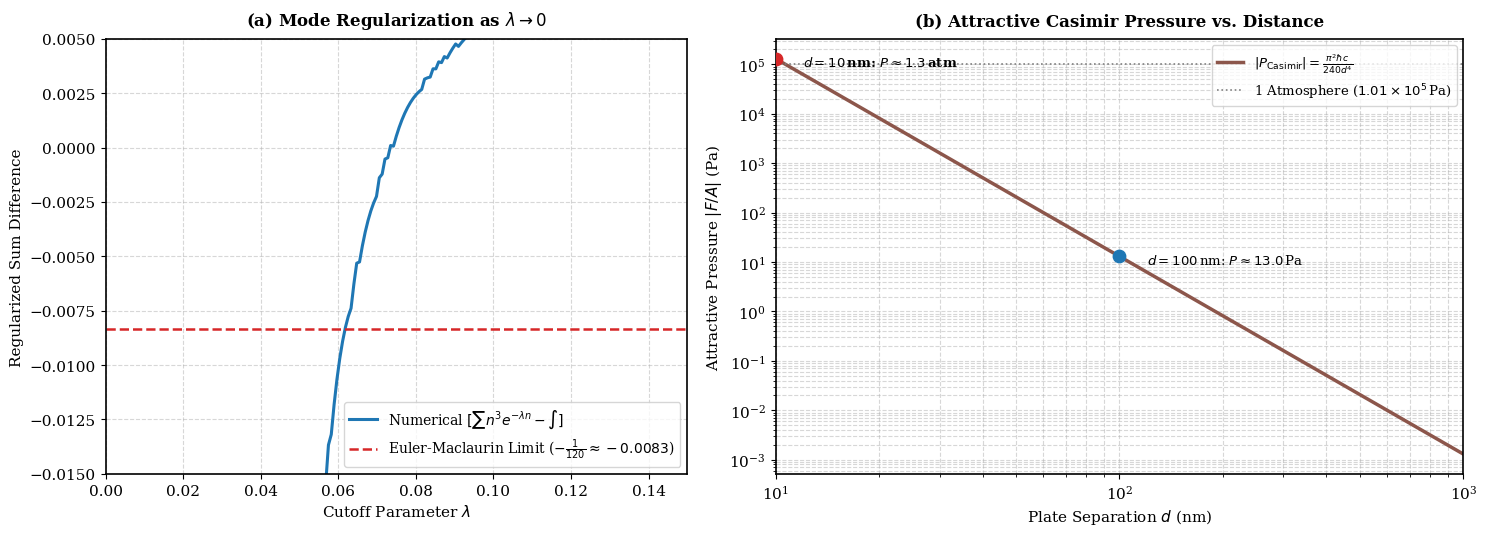

In [2]:
# ==============================================================================
# Simulation 4: Vacuum Zero-Point Energy & Casimir Force Regularization
# Reference: Gerry & Knight, "Introductory Quantum Optics", Chapter 2 (Sec 2.6)
# ==============================================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import hbar, c

# Ensure output directory exists
os.makedirs("figures", exist_ok=True)

# Plot styling configuration
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.linewidth'] = 1.2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.1, 1.3]})

# -------------------------------------------------------------
# 1. Numerical Proof of Regularization (Euler-Maclaurin Limit)
# -------------------------------------------------------------
# The sum to regularize: S(lambda) = sum_{n=1}^{N} n^3 * exp(-lambda * n) - int_0^inf x^3 * exp(-lambda * x) dx
# As lambda -> 0, S(lambda) analytically approaches -1/120 = -0.008333...

lambda_vals = np.linspace(0.005, 0.15, 200)
regularized_diff = []

for lam in lambda_vals:
    # Truncate sum at N where term becomes negligible: exp(-lam * N) < 1e-8
    N_cutoff = int(25.0 / lam)
    n_vec = np.arange(1, N_cutoff + 1)
    
    # Discrete mode sum inside cavity
    discrete_sum = np.sum((n_vec**3) * np.exp(-lam * n_vec))
    # Continuous integral in free space: Gamma(4) / lam^4 = 6 / lam^4
    continuous_integral = 6.0 / (lam**4)
    
    regularized_diff.append(discrete_sum - continuous_integral)

theoretical_limit = -1.0 / 120.0  # Euler-Maclaurin residue

ax1.plot(lambda_vals, regularized_diff, color='#1f77b4', linewidth=2.2, label=r'Numerical $[\sum n^3 e^{-\lambda n} - \int]$')
ax1.axhline(theoretical_limit, color='#d62728', linestyle='--', linewidth=1.8, 
            label=rf'Euler-Maclaurin Limit ($-\frac{{1}}{{120}} \approx {theoretical_limit:.4f}$)')

ax1.set_title(r'(a) Mode Regularization as $\lambda \to 0$', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel(r'Cutoff Parameter $\lambda$', fontsize=11)
ax1.set_ylabel(r'Regularized Sum Difference', fontsize=11)
ax1.set_xlim(0, 0.15)
ax1.set_ylim(-0.015, 0.005)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower right', frameon=True, fontsize=10)

# -------------------------------------------------------------
# 2. Physical Casimir Force (Pressure) vs. Separation Distance
# -------------------------------------------------------------
# Casimir pressure: P = - (pi^2 * hbar * c) / (240 * d^4)
d_vals = np.logspace(-8, -6, 300)  # From 10 nm to 1 micrometer

casimir_const = (np.pi**2 * hbar * c) / 240.0
casimir_pressure = casimir_const / (d_vals**4)  # Absolute magnitude |F/A| in Pascals (N/m^2)

ax2.loglog(d_vals * 1e9, casimir_pressure, color='#8c564b', linewidth=2.5, 
           label=r'$|P_{\mathrm{Casimir}}| = \frac{\pi^2 \hbar c}{240 d^4}$')

# Milestone points
# Point 1: d = 10 nm
p_10nm = casimir_const / ((10e-9)**4)
ax2.scatter([10], [p_10nm], color='#d62728', s=80, zorder=5)
ax2.text(12, p_10nm * 0.7, rf'$d=10\,$nm: $P \approx {p_10nm/1e5:.1f}\,$atm', fontsize=9.5, fontweight='bold')

# Point 2: d = 100 nm
p_100nm = casimir_const / ((100e-9)**4)
ax2.scatter([100], [p_100nm], color='#1f77b4', s=80, zorder=5)
ax2.text(120, p_100nm * 0.7, rf'$d=100\,$nm: $P \approx {p_100nm:.1f}\,$Pa', fontsize=9.5)

# Reference atmospheric pressure (1 atm = 101325 Pa)
ax2.axhline(101325, color='gray', linestyle=':', linewidth=1.2, label=r'1 Atmosphere ($1.01 \times 10^5\,$Pa)')

ax2.set_title(r'(b) Attractive Casimir Pressure vs. Distance', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Plate Separation $d$ (nm)', fontsize=11)
ax2.set_ylabel(r'Attractive Pressure $|F/A|$ (Pa)', fontsize=11)
ax2.set_xlim(10, 1000)
ax2.grid(True, which='both', linestyle='--', alpha=0.5)
ax2.legend(loc='upper right', frameon=True, fontsize=9.5)

plt.tight_layout()

# Save figure to disk for GitHub
output_path = "figures/sim4_casimir_effect.png"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"[OK] Simulation 4 figure successfully saved to: {output_path}")

plt.show()